# 3. Model Perceptron (One-vs-Rest) i porównanie z punktami odniesienia

W tym notatniku łączymy wektoryzację tekstu **TF-IDF** z naszym klasyfikatorem złożonym z trzech binarnych perceptronów (`OneVsRestPerceptron`) i porównujemy jego wyniki na zamrożonym zbiorze testowym z dwoma punktami odniesienia:
1. **Baseline 1 (`MajorityClassBaseline`)** — zawsze przewiduje najczęstszą klasę (`neutral`).
2. **Baseline 2 (`KeywordBaseline`)** — zlicza wystąpienia słów ze słownika finansowego.


In [3]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.baseline import MajorityClassBaseline, KeywordBaseline
from src.perceptron import OneVsRestPerceptron

train_df = pd.read_csv(PROJECT_ROOT / "data/processed/train.csv")
test_df = pd.read_csv(PROJECT_ROOT / "data/processed/test.csv")

print(f"Zbiór uczący: {len(train_df)} zdań")
print(f"Zbiór testowy: {len(test_df)} zdań")

Zbiór uczący: 2758 zdań
Zbiór testowy: 690 zdań


In [4]:
# Dopasowanie TF-IDF WYŁĄCZNIE na zbiorze uczącym
vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 2),
    stop_words="english",
)
X_train = vectorizer.fit_transform(train_df["sentence"])
X_test = vectorizer.transform(test_df["sentence"])

# OneVsRestPerceptron
ovr_model = OneVsRestPerceptron(learning_rate=0.1, n_epochs=15, random_state=42)
ovr_model.fit(X_train, train_df["label"])
preds_ovr = ovr_model.predict(X_test)

# Punkty odniesienia
preds_maj = MajorityClassBaseline().fit(train_df["label"]).predict(test_df["sentence"])
preds_kw = KeywordBaseline().fit().predict(test_df["sentence"])

summary_df = pd.DataFrame([
    {
        "Model": "Baseline 1: Klasa większościowa (neutral)",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_maj) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_maj, average="macro"), 4),
    },
    {
        "Model": "Baseline 2: Słownik słów kluczowych",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_kw) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_kw, average="macro"), 4),
    },
    {
        "Model": "Model 3: Własny OneVsRestPerceptron (bazowy)",
        "Accuracy (%)": round(accuracy_score(test_df["label"], preds_ovr) * 100, 2),
        "Macro-F1": round(f1_score(test_df["label"], preds_ovr, average="macro"), 4),
    },
])

display(summary_df)
print("\nSzczegółowy raport klasyfikacji (OneVsRestPerceptron):")
print(classification_report(test_df["label"], preds_ovr, digits=4))


,Model,Accuracy (%),Macro-F1
0,Baseline 1: Klasa większościowa (neutral),62.03,0.2552
1,Baseline 2: Słownik słów kluczowych,76.81,0.6804
2,Model 3: Własny OneVsRestPerceptron (bazowy),78.26,0.7174



Szczegółowy raport klasyfikacji (OneVsRestPerceptron):
              precision    recall  f1-score   support

    negative     0.7818    0.5119    0.6187        84
     neutral     0.8555    0.8575    0.8565       428
    positive     0.6311    0.7303    0.6771       178

    accuracy                         0.7826       690
   macro avg     0.7561    0.6999    0.7174       690
weighted avg     0.7886    0.7826    0.7813       690



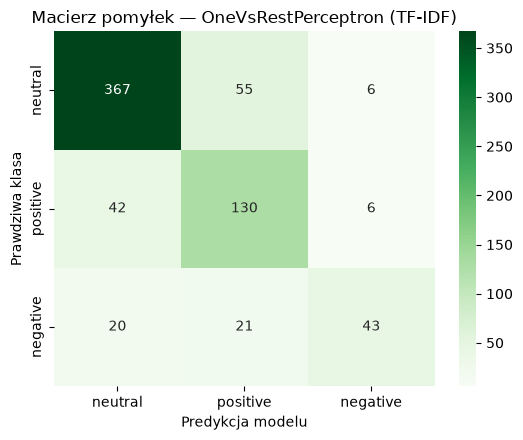

In [5]:
labels_order = ["neutral", "positive", "negative"]
cm = confusion_matrix(test_df["label"], preds_ovr, labels=labels_order)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=labels_order, yticklabels=labels_order)
plt.title("Macierz pomyłek — OneVsRestPerceptron (TF-IDF)")
plt.xlabel("Predykcja modelu")
plt.ylabel("Prawdziwa klasa")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "results/perceptron_cm.png", dpi=150)
plt.show()